# **Malaria Dataset & Project Objective**

**Dataset Description:**  
Malaria is a life-threatening disease caused by Plasmodium parasites, which are transmitted to humans through the bites of infected female Anopheles mosquitoes. Despite being both preventable and curable, malaria remains a major global health challenge, disproportionately affecting vulnerable populations.

In 2018, an estimated 228 million malaria cases were recorded worldwide, resulting in approximately 405,000 deaths. Children under the age of five are the most at risk, accounting for 67% (272,000) of all malaria-related deaths in that year. The burden of malaria is particularly severe in the WHO African Region, which accounted for 93% of global malaria cases and 94% of malaria deaths in 2018.

 The **Malaria dataset** used in this project contains 2033 instances and the following columns:  

- **Country**: The name of the country where malaria cases were recorded.  
- **Year**: The specific year of the recorded data.  
- **No. of Cases**: The total number of reported malaria cases in that country for the given year.  
- **WHO Region**: The World Health Organization (WHO) region to which the country belongs (e.g., African Region, South-East Asia Region).  

**Project Objective:**  
The objective of this project is to analyze malaria-related data to identify trends, risk factors, and high-burden regions using Time Series Models. This will help in developing predictive models for malaria spread, improving early detection, and optimizing prevention strategies to reduce its impact.

**1. Install and Load Required Packages**

Before working with the dataset, install and load essential R packages:

In [ ]:
install.packages(c("tidyverse", "lubridate", "forecast", "tseries", "ggplot2"))
install.packages("fma")
install.packages("TSA")
install.packages("MASS")
install.packages("lmtest")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘leaps’, ‘locfit’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(tidyverse)    # For data manipulation
library(lubridate)    # For handling date-time formats
library(forecast)     # For time series forecasting
library(tseries)      # For statistical tests on time series
library(ggplot2)
library(fma)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



# **Loading and Exploing the Dataset**  
This code reads the malaria dataset from a CSV file and displays the first few rows to inspect its structure.

In addition to an overview of the dataset's structure and key statistics. `glimpse()` displays column types and sample values, while `summary()` provides statistical summaries such as mean, min, max, and quartiles.

In [ ]:
# Load the dataset
malaria_data <- read_csv("malaria-dataset.csv")

# View the first few rows
head(malaria_data)

Rows: 2033 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): Country, WHO Region
dbl (2): Year, No. of cases

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Country,Year,No. of cases,WHO Region
<chr>,<dbl>,<dbl>,<chr>
Afghanistan,2018,29.01,Eastern Mediterranean
Algeria,2018,0.00,Africa
Angola,2018,228.91,Africa
Argentina,2018,0.00,Americas
Armenia,2018,0.00,Europe
Azerbaijan,2018,0.00,Europe


In [ ]:
glimpse(malaria_data)   # Overview of dataset structure
summary(malaria_data)   # Summary statistics


Rows: 2,033
Columns: 4
$ Country        <chr> "Afghanistan", "Algeria", "Angola", "Argentina", "Armen…
$ Year           <dbl> 2018, 2018, 2018, 2018, 2018, 2018, 2018, 2018, 2018, 2…
$ `No. of cases` <dbl> 29.01, 0.00, 228.91, 0.00, 0.00, 0.00, 0.69, 0.01, 386.…
$ `WHO Region`   <chr> "Eastern Mediterranean", "Africa", "Africa", "Americas"…


   Country               Year       No. of cases     WHO Region       
 Length:2033        Min.   :2000   Min.   :  0.00   Length:2033       
 Class :character   1st Qu.:2004   1st Qu.:  0.52   Class :character  
 Mode  :character   Median :2009   Median : 11.15   Mode  :character  
                    Mean   :2009   Mean   :109.19                     
                    3rd Qu.:2014   3rd Qu.:199.99                     
                    Max.   :2018   Max.   :743.51                     

# **Preparing and Visualizing the Time Series Data**
This code ensures the dataset is correctly formatted, renames columns ("No. of cases" to "Malaria_Incidence" for clarity), handles missing values, converts the Year column to numeric, and creates a time series object for malaria incidence. Finally, it plots the malaria incidence over time.

In [ ]:
# Convert Year to numeric
malaria_data <- malaria_data %>%
  mutate(Year = as.numeric(as.character(Year)))

# Rename 'No. of cases' to 'Malaria_Incidence'
malaria_data <- malaria_data %>%
  rename(Malaria_Incidence = `No. of cases`)

# Ensure column names are correct
colnames(malaria_data)

# Check for missing values
summary(malaria_data$Malaria_Incidence)


[1] "Country"           "Year"              "Malaria_Incidence"
[4] "WHO Region"

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    0.52   11.15  109.19  199.99  743.51 

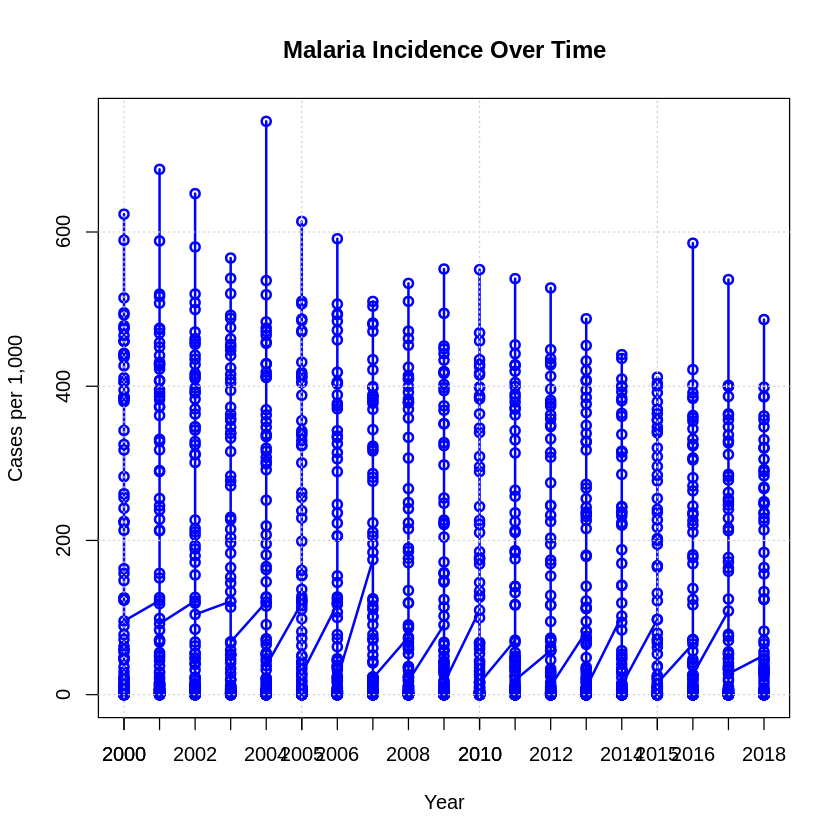

In [ ]:

# Create the time series
plot(malaria_data$Year, malaria_data$Malaria_Incidence,
     type="o", col="blue", lwd=2,
     main="Malaria Incidence Over Time",
     xlab="Year", ylab="Cases per 1,000")
axis(1, at = seq(2000, 2018, by = 1))
grid()


## **Interpretation of the Time Series**

**General Trend:**

- The malaria incidence appears to be decreasing over time from 2000 to 2018.

- The highest values were observed in the early 2000s, but over time, the cases per 1,000 people have generally declined.

**Seasonality & Fluctuations:**

- There are annual peaks in incidence, suggesting periodic outbreaks or seasonal patterns.

- The vertical lines indicate a large spread of cases in some years, meaning variability across different regions or populations.

**Notable Observations:**

- The highest spikes occur between 2000 and 2005, indicating that malaria was more severe in those years.

- From 2010 onward, the fluctuations are smaller, and the overall incidence seems to stabilize at a lower level.

- There is no sudden resurgence, meaning malaria control measures might have been effective.

**Mean:**

- The central tendency of malaria incidence seems to decrease over time.

- In the early 2000s, the average level was higher, but as time progresses, the overall level appears to stabilize at a lower point. This suggests that the mean is not constant—it likely exhibits a downward trend.

**Variance:**

- The vertical spread of data points is wider in the early years (2000–2005), meaning higher variance.

- As time progresses, the fluctuations seem to reduce slightly, but variance remains noticeable.

- This suggests that variance might be decreasing, but it does not appear completely constant.

**Does This Time Series Look Stationary?**
- A stationary time series has a constant mean and variance over time.

- In this case, the mean is decreasing, and the variance appears to change over time.

- **Conclusion:** This malaria incidence time series is likely non-stationary because the mean is not constant.

In order to make the plot clearer so that we can explore more information about the time series represented. Here is this modification:

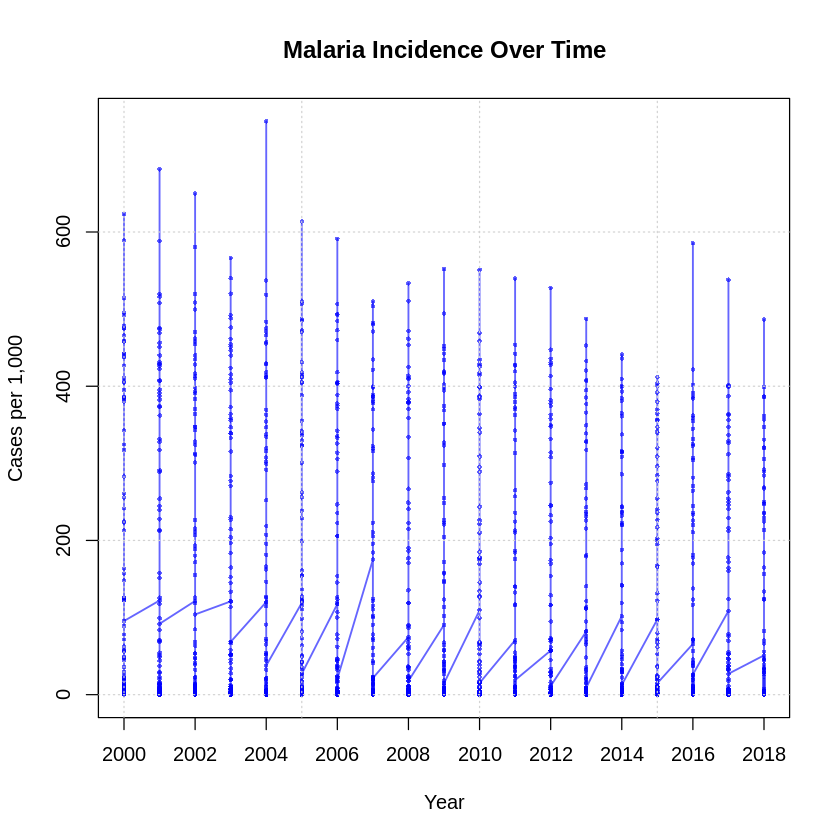

In [ ]:

# Create the time series
plot(malaria_data$Year, malaria_data$Malaria_Incidence,
      col=rgb(0, 0, 1, 0.6),  lwd=1.5, type="o", pch=16, cex=0.5, xaxt="n",
     main="Malaria Incidence Over Time",
     xlab="Year", ylab="Cases per 1,000")
axis(1, at = seq(2000, 2018, by = 2))
grid()


### **Rolling Statistics for Malaria Incidence**  
This code calculates and visualizes the **rolling mean** and **rolling standard deviation** over a 5-year window to observe trends and variance stability in malaria incidence. The rolling mean (blue) and rolling standard deviation (red) help assess stationarity.

### **Interpretation of the Rolling Mean and Variance Plot (2000-2018)**

1. **Rolling Mean (Blue Line) Trend:**
   - The rolling mean represents the average number of malaria cases over a moving window of 5 years.
   - Initially, from 2000 to 2005, the mean remains relatively low.
   - After 2005, it starts to increase steadily, with a more noticeable upward trend from around 2010 onwards.
   - This suggests that malaria incidence has generally increased over time.

2. **Rolling Standard Deviation (Red Line) Trend:**
   - The rolling standard deviation (variance indicator) represents the fluctuation in malaria cases.
   - From 2000 to 2005, the standard deviation is relatively low, indicating stable (but possibly low) malaria cases.
   - Around 2005, there's a drop, possibly due to a period of reduced cases.
   - After 2005, the variance increases, showing greater fluctuations in malaria cases, meaning that the data has become more unstable.
   - Around 2015, the variance slightly declines, suggesting a stabilization in case fluctuations.

3. **Overall Observations:**
   - The black line (original series) shows periodic spikes, indicating occasional years with very high malaria incidence.
   - The increase in both the rolling mean and rolling standard deviation suggests that not only are malaria cases increasing over time, but the fluctuations in cases have also become more pronounced.
   - The peaks in the original series align with increases in both the rolling mean and rolling standard deviation, reinforcing the idea that malaria incidence is becoming more unpredictable.

### **Conclusion**
The data suggests a general upward trend in malaria cases over time, accompanied by increasing variability. This could indicate that malaria outbreaks have become more severe or that reporting and detection have improved, leading to greater observed fluctuations.

### **Is there Seasonality?**
- The rolling mean and rolling standard deviation both increase over time, which suggests a trend rather than seasonality.
- It seems to follow an increasing trend with irregular spikes, likely caused by specific outbreak years rather than a fixed seasonal cycle.

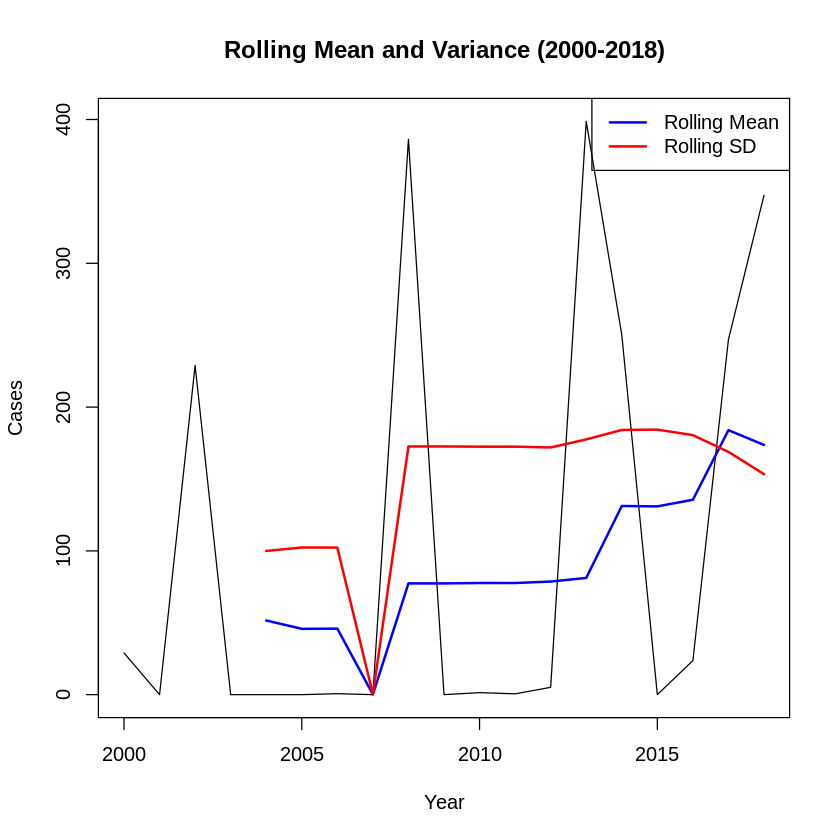

In [ ]:
library(zoo)  # Load the zoo package for rolling functions

# Subset the time series data from 2000 to 2018
start_year <- 2000
end_year <- 2018
malaria_subset <- window(malaria_ts, start = start_year, end = end_year)

# Compute rolling mean and standard deviation (window size = 5 years)
rolling_mean <- rollmean(malaria_subset, k = 5, fill = NA, align = "right")
rolling_sd <- rollapply(malaria_subset, width = 5, FUN = sd, fill = NA, align = "right")

# Plot original series with rolling statistics
plot(malaria_subset, main = "Rolling Mean and Variance (2000-2018)", ylab = "Cases", xlab = "Year", col = "black")
lines(rolling_mean, col = "blue", lwd = 2)  # Rolling mean (blue)
lines(rolling_sd, col = "red", lwd = 2)  # Rolling standard deviation (red)
legend("topright", legend = c("Rolling Mean", "Rolling SD"), col = c("blue", "red"), lwd = 2)


###**Variance Stabilization**
According to the tests conducted earlier, it appears that **variance stabilization is necessary**, as the data exhibits heteroscedasticity, meaning that the variance is not constant over time. This can negatively impact the performance of time series models, including ARIMA, as they generally assume stationarity in both mean and variance. To address this issue, a **transformation is applied**, such as the **Box-Cox transformation**, to stabilize the variance and improve the model's accuracy. By applying this transformation, the data becomes more suitable for forecasting, ensuring that the predictive model can better capture the underlying patterns and produce more reliable results.


Attaching package: ‘MASS’


The following objects are masked from ‘package:fma’:

    cement, housing, petrol


The following object is masked from ‘package:dplyr’:

    select




[1] "Optimal lambda: -0.0606060606060606"


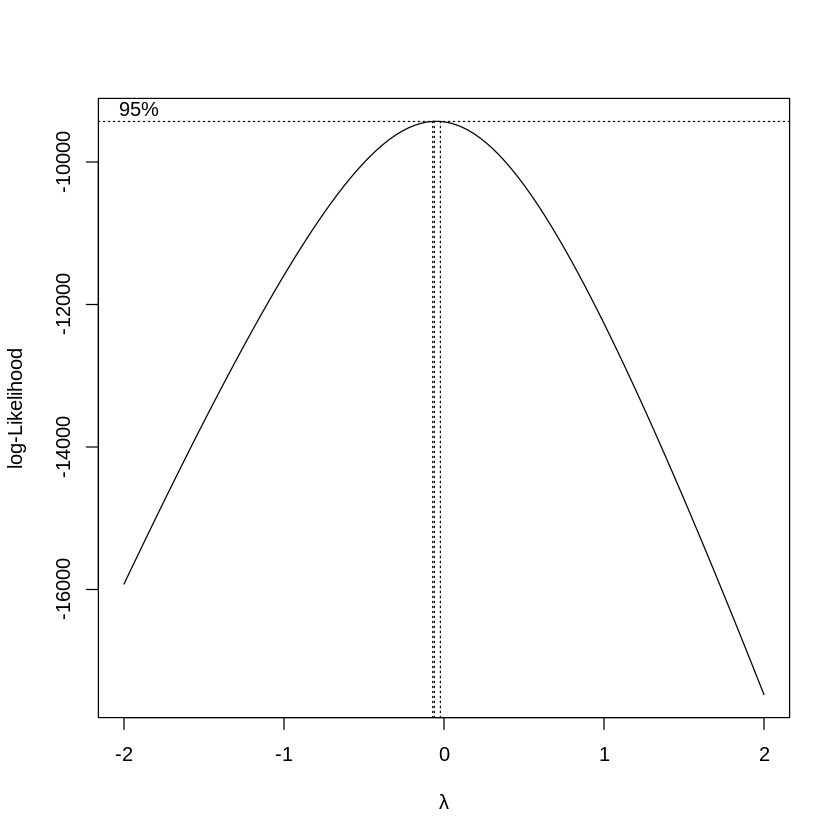

In [ ]:
# Load the MASS package
library(MASS)

# Shift residuals by adding a constant to make them positive
shifted_model <- malaria_ts + abs(min(malaria_ts)) + 1

# Apply Box-Cox transformation
lambda_values <- seq(-2, 2, by = 0.1)
bc_results <- boxcox(lm(shifted_model ~ 1), lambda = lambda_values)

# Find optimal lambda
optimal_lambda <- bc_results$x[which.max(bc_results$y)]
print(paste("Optimal lambda:", optimal_lambda))

##**ACF and PACF Interpretation:**
**For ACF**
- Lag 0 is 1: The first vertical bar at lag 0 is equal to 1 means the time series is perfectly correlated with itself.

- Autocorrelation drops: After the first one most bars fall within the blue confidence bounds, suggesting weak autocorrelation.

- No strong significant lags: Since most lags remain within the confidence limits, there’s no strong seasonal pattern or long-term dependence.

- Random fluctuations: The lack of clear patterns suggests the time series may be stationary or close to white noise.

**For PACF**

- Some lags (e.g., around 6, and 25) exceed the confidence interval, meaning they have a strong direct correlation with the current value.

- The strength of correlation decreases as lag increases.

- The PACF values drop sharply after a few significant lags.This suggests that past values beyond those initial lags do not contribute much to predicting the current value.

- The values beyond the first few significant lags fluctuate around zero, staying mostly within the confidence interval. This suggests that additional lags do not have a direct impact.

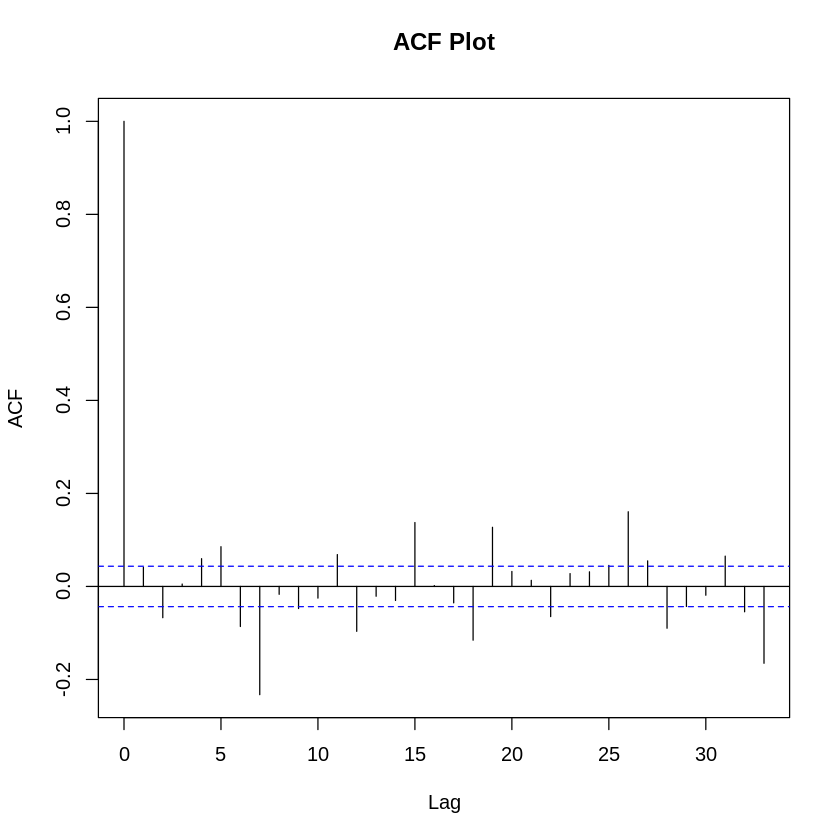

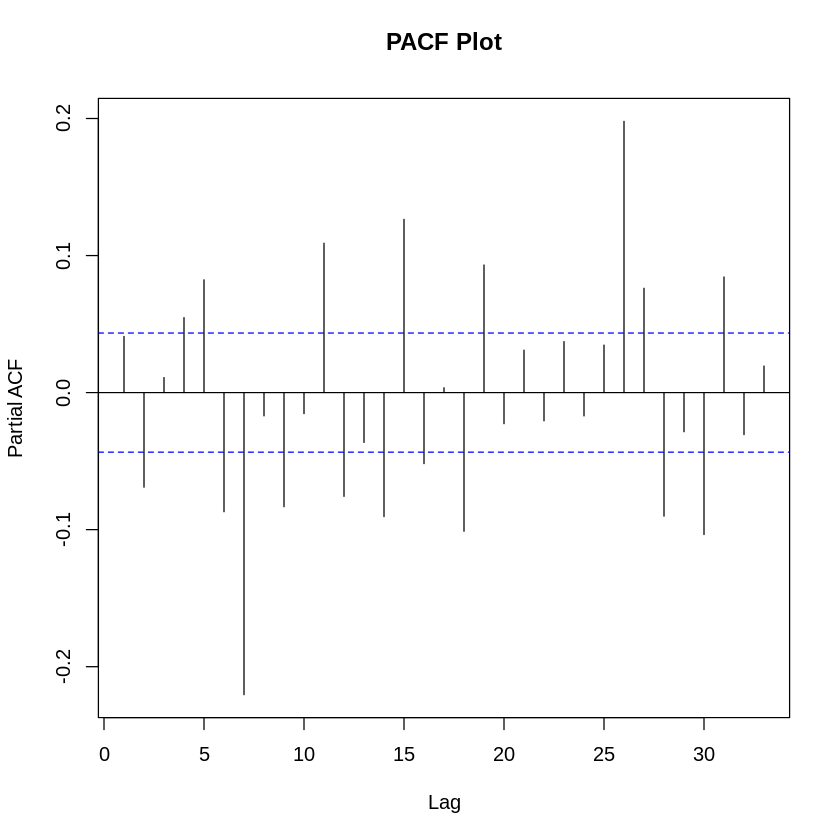

In [ ]:
# Apply Box-Cox transformation, handling potential Inf/NaN
malaria_tsf <- BoxCox(malaria_ts, lambda = -0.060606060606060)

# Interpolate to fill NA values if they exist within the time series
malaria_tsf <- na.approx(malaria_tsf)

# Now proceed with ACF and PACF plots
par(mfrow = c(1, 1))  # Plot side-by-side
acf(malaria_tsf, main = "ACF Plot")
pacf(malaria_tsf, main = "PACF Plot")

##**Stationarity Test**
The adf.test(malaria_ts) function performs **the Augmented Dickey-Fuller (ADF) test**, which checks for stationarity in a time series.



### **Interpretation of the ADF Test Results:**

**Test Statistic (Dickey-Fuller) = -15.942**
- This value is much lower than the critical values at common significance levels (e.g., -3.43 at 1% significance level).

- This strongly suggests that the time series is stationary.

**p-value = 0.01**

- Since p-value < 0.05, we reject the null hypothesis (which states that the series is non-stationary).

- This confirms that the malaria incidence time series does not have a unit root and is stationary.

**Lag order = 12**

- The test used 12 lags to account for autocorrelation in the data.

- This means past values up to 12 time steps were considered to improve the reliability of the test.

**Conclusion:**
 The malaria incidence time series is stationary.

In [ ]:
adf.test(malaria_tsf)


Warning message in adf.test(malaria_tsf):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  malaria_tsf
Dickey-Fuller = -15.942, Lag order = 12, p-value = 0.01
alternative hypothesis: stationary


##**Why to Use Differencing?**
Although the time series is already stationary, determining the appropriate model for forecasting remains challenging. The PACF plot does not provide clear insights for selecting the autoregressive order (*p*) of the ARIMA model, making it difficult to identify the best-fitting parameters. To address this, I applied first differencing to the series and re-plotted the ACF and PACF.

 This step helps obtain more distinct patterns, allowing for a clearer determination of the model parameters needed for accurate forecasting.

**Note:** I opted for the ARIMA model since it is evident from the time series representation that the data does not follow a linear pattern, making linear or deterministic time models unsuitable for capturing its underlying structure.

In [ ]:
diff_ts <- diff(malaria_tsf)
adf.test(diff_ts)  # Re-test stationarity


Warning message in adf.test(diff_ts):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  diff_ts
Dickey-Fuller = -20.749, Lag order = 12, p-value = 0.01
alternative hypothesis: stationary


##**Interpretation of ACF and PACF of the first Difference:**
**For ACF**
- There is no big change we still have the bar at lag 0 that equals 1 and another bar has increased at lag 1 which may sugget an MA model with parameter **q** equals to 1.

**For PACF**
- The PACF shows a significant first lag (negative value), followed by a gradual decay.

- Many lags are below the significance threshold (blue dashed lines), but a persistent downward trend is visible.

- This pattern suggests a higher-order AR process rather than a simple AR(1) model.


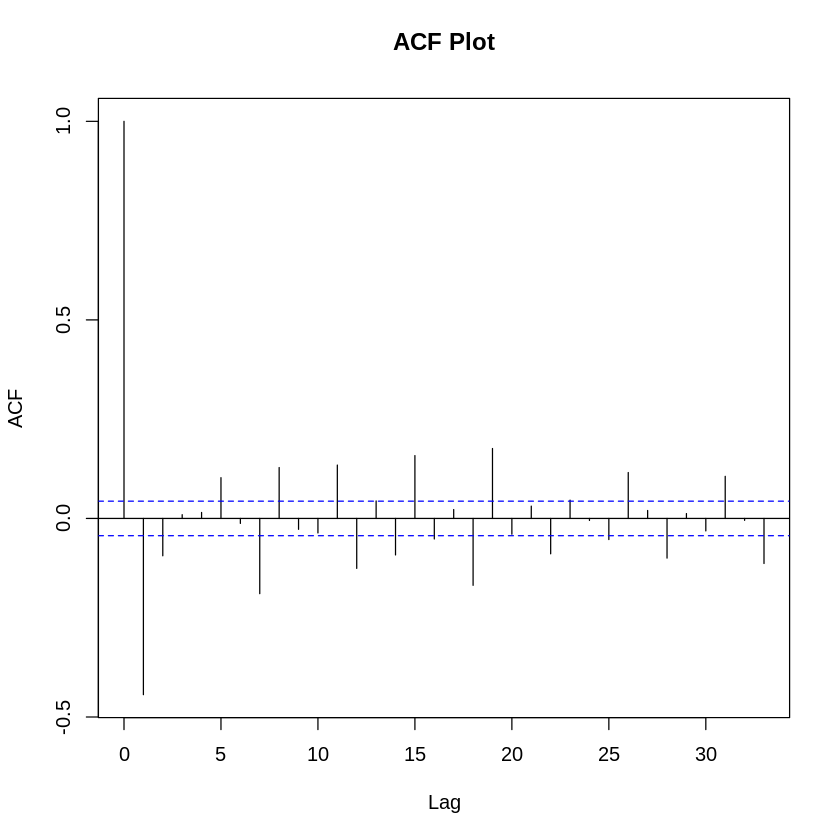

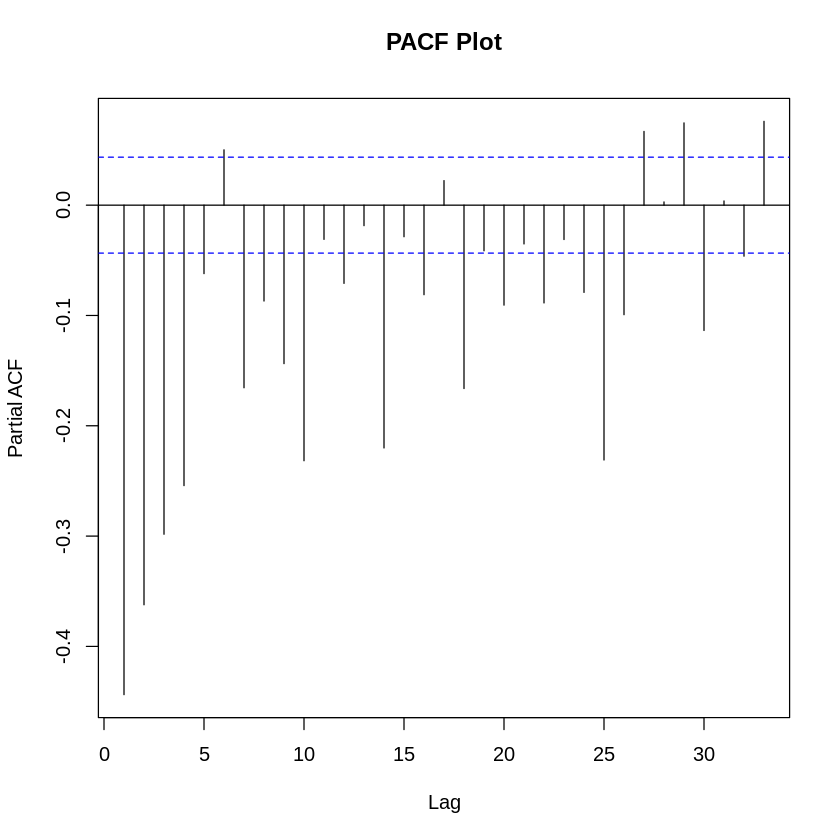

In [ ]:
par(mfrow = c(1, 1))  # Plot side-by-side
acf(diff_ts, main = "ACF Plot")
pacf(diff_ts, main = "PACF Plot")

**Splitting the Dataset into Traing Set and Testing Set:**

- In order to facilitate the forecasting operation only 10 instances will be used to test.

In [ ]:
train <- malaria_tsf[1:(length(malaria_ts) - 10)]  # All but the last 10 observations
test <- tail(malaria_tsf, 10)   # Last 10 observations for testing

# **Model Fitting**

From the previous results of the **ACF and PACF plots** and the **ADF test**, several **ARIMA models** will be fitted to the data. To determine the most suitable model, criteria such as **Akaike Information Criterion (AIC)** and **Bayesian Information Criterion (BIC)** will be used. The model with the lowest AIC and BIC values will be selected as the best fit for forecasting.

Using different parameters p, q and d in order to find the best mode.

The estimated values of the parameters were changed based on the summary results of every model fitted. By interpreting the results of ME, RMSE, MASE, and ACF1, I have decided to increase or decrease the parameters to find the most apprpriate model.

In [ ]:
model1 <- arima(train, order = c(2, 0, 0))  # AR(2) Model
summary(model1)


Call:
arima(x = train, order = c(2, 0, 0))

Coefficients:
         ar1      ar2  intercept
      0.0463  -0.0678     2.4127
s.e.  0.0222   0.0222     0.0538

sigma^2 estimated as 6.112:  log likelihood = -4701.64,  aic = 9411.28

Training set error measures:
                       ME     RMSE      MAE MPE MAPE      MASE         ACF1
Training set 0.0002915081 2.472307 2.017592 Inf  Inf 0.7792269 0.0009063987

In [ ]:
model2 <- arima(train, order=c(4,0,1))
summary(model2)



Call:
arima(x = train, order = c(4, 0, 1))

Coefficients:
         ar1      ar2     ar3     ar4      ma1  intercept
      0.2582  -0.0744  0.0250  0.0578  -0.2127     2.4135
s.e.  0.1228   0.0237  0.0244  0.0225   0.1213     0.0589

sigma^2 estimated as 6.088:  log likelihood = -4697.59,  aic = 9409.17

Training set error measures:
                        ME     RMSE     MAE MPE MAPE      MASE         ACF1
Training set -0.0007677056 2.467347 2.01498 Inf  Inf 0.7782183 -0.002444408

In [ ]:
model3 <- arima(train ,order=c(1,1,1))
summary(model3)



Call:
arima(x = train, order = c(1, 1, 1))

Coefficients:
         ar1      ma1
      0.0375  -0.9963
s.e.  0.0223   0.0015

sigma^2 estimated as 6.13:  log likelihood = -4704.68,  aic = 9415.35

Training set error measures:
                     ME     RMSE      MAE MPE MAPE     MASE        ACF1
Training set 0.07453709 2.475301 2.033513 Inf  Inf 0.785376 0.001481903

In [ ]:
model4 <- arima(train ,order=c(2,1,0))
summary(model4)


Call:
arima(x = train, order = c(2, 1, 0))

Coefficients:
          ar1      ar2
      -0.6037  -0.3622
s.e.   0.0208   0.0208

sigma^2 estimated as 8.211:  log likelihood = -4997.94,  aic = 10001.88

Training set error measures:
                       ME     RMSE     MAE MPE MAPE      MASE       ACF1
Training set -0.004542272 2.864719 2.28499 Inf  Inf 0.8825006 -0.1065059

##**Model Comparison and Selection**

To identify the best-fitting **ARIMA model**, multiple models are evaluated using **Akaike Information Criterion (AIC)** and **Bayesian Information Criterion (BIC)**. The AIC and BIC values are extracted for each model and stored in a comparison table. The model with the **lowest AIC and BIC** is selected as the most suitable for forecasting.

**Results:**
- For AIC Test: the best model is Model 2 ARIMA(4,0,1)
- For BIC Test: the best model is Model 3 ARIMA(1,1,1)

In [ ]:
# List of models
models <- list(model1, model2, model3, model4)
model_names <- c("Model 1", "Model 2", "Model 3", "Model 4")

# Extract AIC and BIC for each model
aic_values <- sapply(models, AIC)
bic_values <- sapply(models, BIC)

# Combine results into a data frame
comparison_df <- data.frame(
  Model = model_names,
  AIC = aic_values,
  BIC = bic_values
)

# Print results
print(comparison_df)

# Find the best model based on AIC and BIC
best_aic_model <- model_names[which.min(aic_values)]
best_bic_model <- model_names[which.min(bic_values)]

cat("Best Model based on AIC:", best_aic_model, "\n")
cat("Best Model based on BIC:", best_bic_model, "\n")


    Model       AIC       BIC
1 Model 1  9411.280  9433.730
2 Model 2  9409.171  9448.458
3 Model 3  9415.350  9432.186
4 Model 4 10001.877 10018.712
Best Model based on AIC: Model 2 
Best Model based on BIC: Model 3 


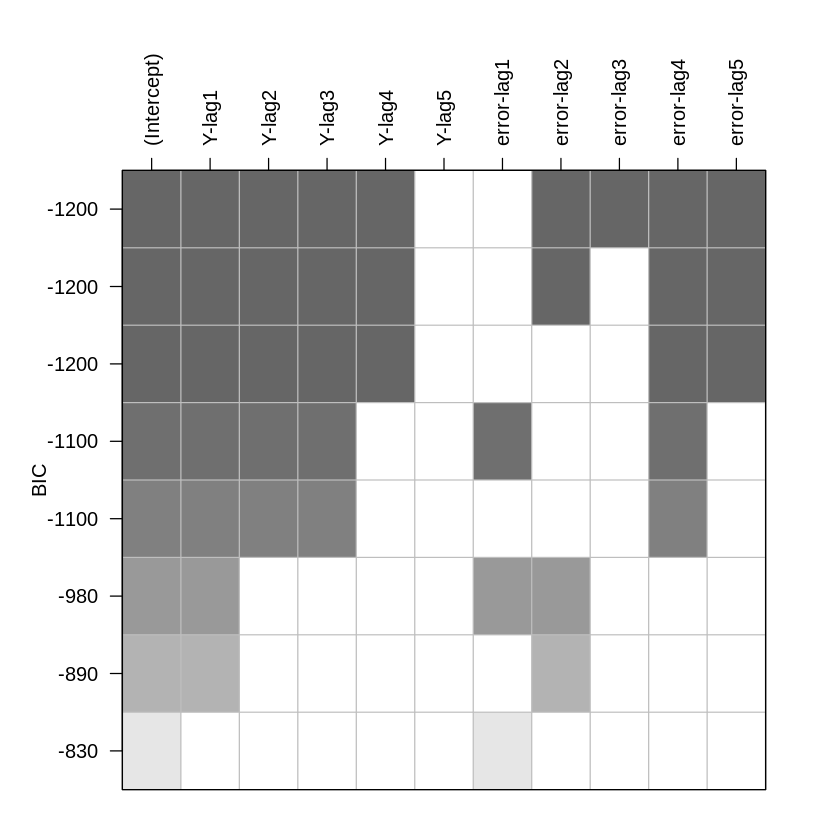

In [ ]:
plot(TSA::armasubsets(diff(train), nar = 5, nma = 5))


#**Residulas Analysis:**

After selecting the best-fitting model, its **residuals** are extracted for further diagnostic checks. These residuals will be analyzed to ensure they exhibit properties of **white noise**—independence, normality, and constant variance—before proceeding with forecasting.

In [ ]:
residuals_model <- residuals(model2)


###**Interpretation of the Residuals Over Time Plot**


- The residuals oscillate around zero, which suggests that the model is unbiased.

- The spread of the residuals appears fairly consistent over time, which indicates that the model maintains a stable variance.(Homoscedasticity)

- However, there are some fluctuations in certain areas, so checking for heteroscedasticity (changing variance) might be necessary.


- The plot does not show clear patterns, which suggests that the residuals are mostly white noise.

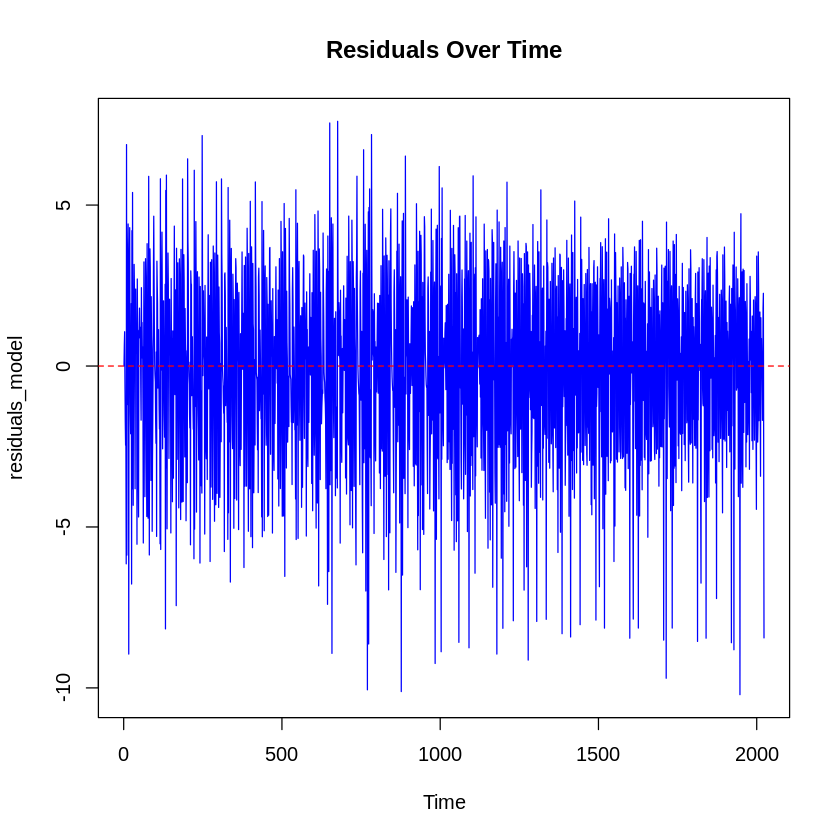

In [ ]:
# Residuals time plot
plot(residuals_model , type="l", main="Residuals Over Time", col="blue")
abline(h=0, col="red", lty=2)


**Breusch-Pagan Test (Statistical Test)**

The Breusch-Pagan test formally checks for heteroscedasticity.
p-value > 0.05 → Fail to reject
𝐻0: variance is constant.

p-value < 0.05 → Reject
𝐻0 variance is not constant (heteroscedasticity).

**Results:** p-value = 0.06813 > 0.05 then the variance is constant no need to stablize the variance for the residuals.

In [ ]:
# Load the lmtest package
library(lmtest)

# Perform Breusch-Pagan test on residuals of model2
bptest(lm(model2$residuals ~ fitted(model2)))  # Run Breusch-Pagan Test


	studentized Breusch-Pagan test

data:  lm(model2$residuals ~ fitted(model2))
BP = 3.3276, df = 1, p-value = 0.06813


**We need to work with the standardized residulas:**

In [ ]:
# Compute standard deviation of residuals
std_dev <- sd(residuals_model)

# Compute standardized residuals
standardized_residuals <- residuals_model / std_dev

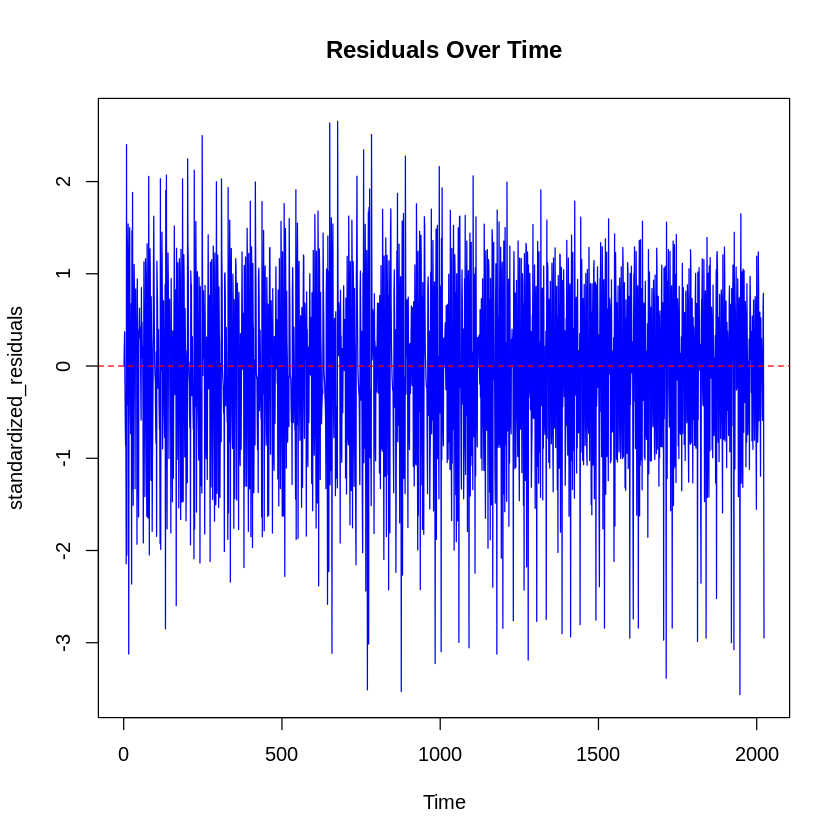

In [ ]:
plot(standardized_residuals , type="l", main="Residuals Over Time", col="blue")
abline(h=0, col="red", lty=2)


### Interpretation of ACF of Residuals:
- The **autocorrelation function (ACF) plot** shows the correlation of residuals with their own lagged values.
- Most of the autocorrelation values fall within the confidence bounds , meaning no significant autocorrelation. (It mainly looks like the ACF plot of the wihte noise).
- This suggests that the residuals are mostly uncorrelated, indicating that the model captures most of the patterns in the data.

### Interpretation of PACF of Residuals:
- The values are mostly within the confidence bounds, with some small spikes, but there is no strong pattern.
- This suggests that there are no significant leftover dependencies in the residuals.

### Conclusion:
- Since both ACF and PACF show no clear pattern and most values fall within the confidence limits, the residuals appear to be **uncorrelated and random**.
- This indicates that the model is well-fitted and does not suffer from autocorrelation issues.
- The residuals are likely **white noise**, which is a good sign of a properly specified model.

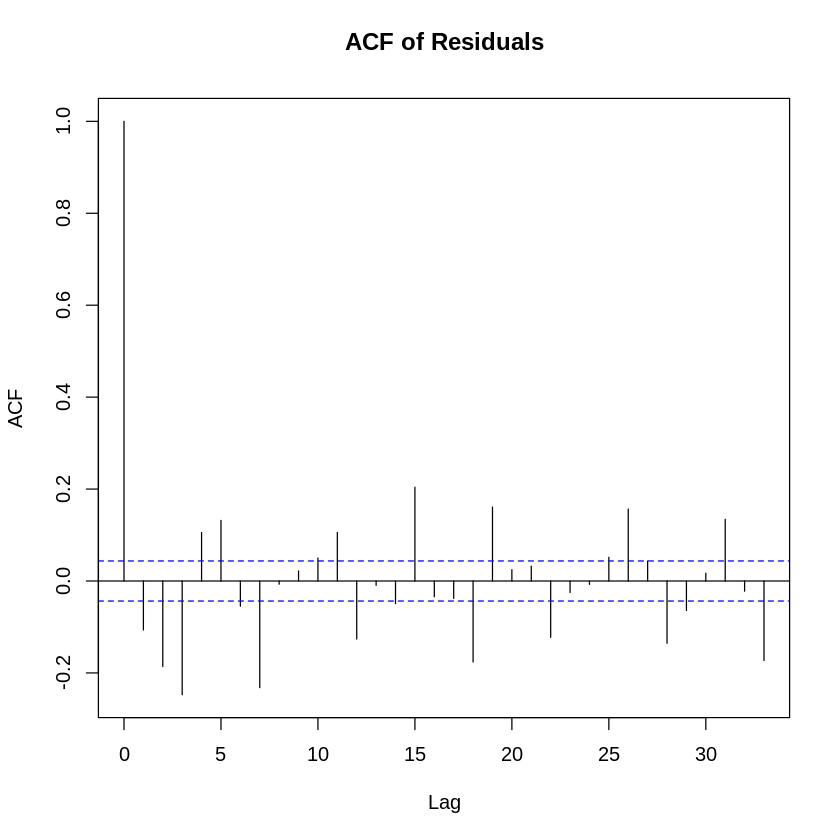

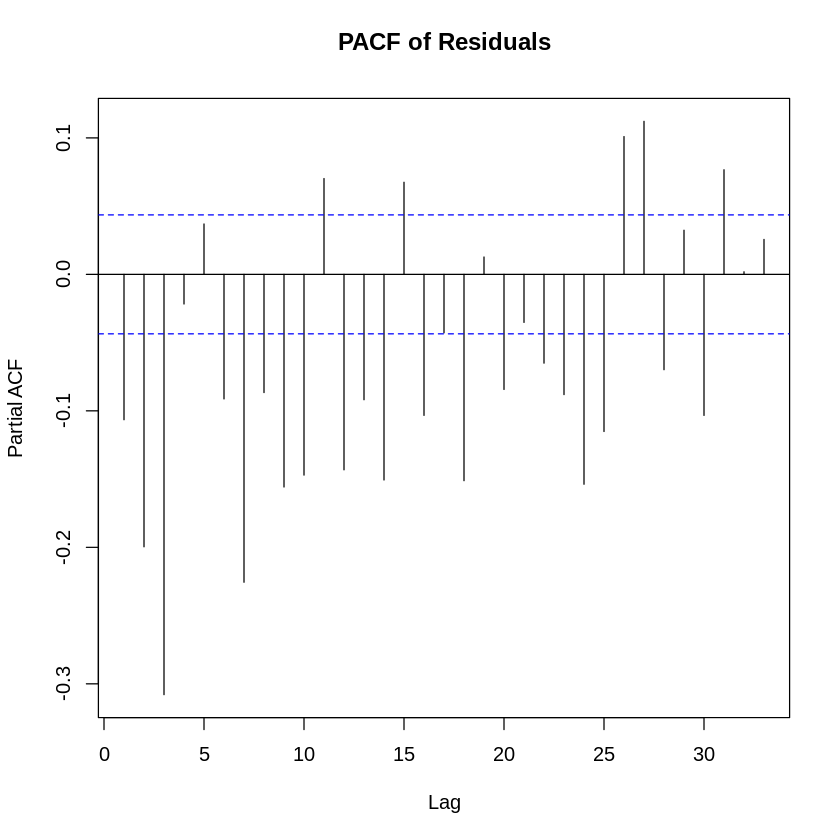

In [ ]:
par(mfrow=c(1,1))  # Set layout for two plots
acf(standardized_residuals , main="ACF of Residuals")
pacf(standardized_residuals , main="PACF of Residuals")
par(mfrow=c(1,1))  # Reset layout


### **Interpretation of Histogram of Residuals:**
- The histogram shows the distribution of residuals.
- It is **approximately bell-shaped and symmetric**, indicating that the residuals follow a normal distribution.
- There are no extreme outliers or strong skewness.
- This suggests that the residuals are **normally distributed**, which is a good assumption for many time series models.

### **Interpretation of QQ Plot of Residuals:**
- The **QQ plot** compares the residuals against a theoretical normal distribution.
- The points mostly lie along the **red diagonal line**, which indicates that the residuals are normally distributed.
- There are slight deviations at the extreme ends, suggesting minor departures from normality, but overall, the fit is good.

### **Conclusion:**
- The residuals are **approximately normally distributed**, which supports the assumption of a well-fitted model.
- There are no significant outliers or skewness issues.
- Since normality is a key assumption for many forecasting and statistical inference methods, this confirms the model's validity.

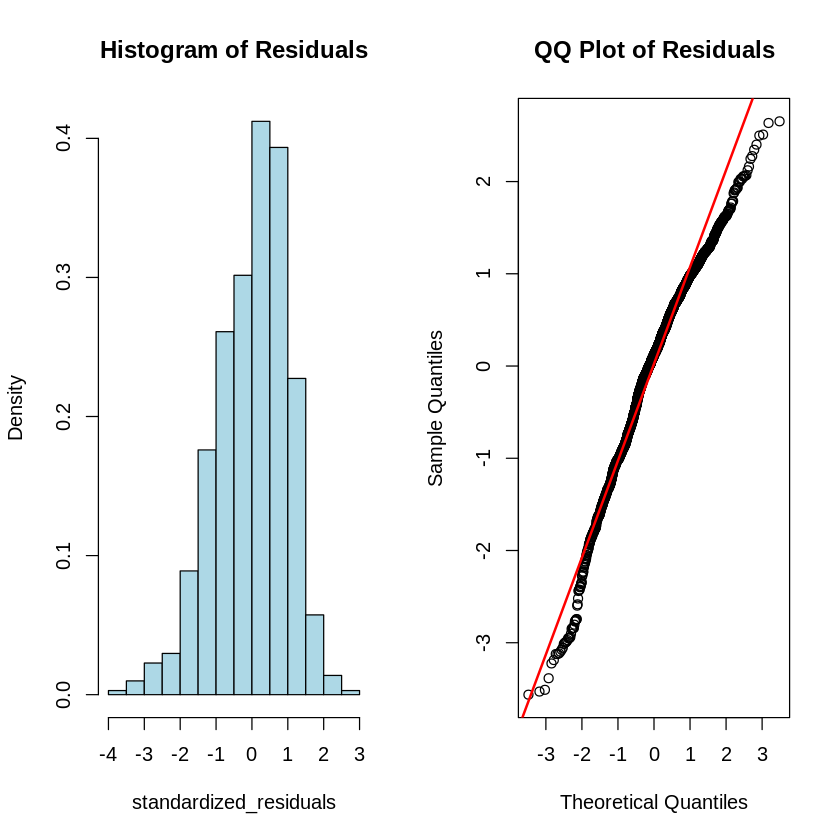

In [ ]:
par(mfrow=c(1,2))  # Set layout for two plots
hist(standardized_residuals , breaks=20, probability=TRUE, main="Histogram of Residuals", col="lightblue")
qqnorm(standardized_residuals , main="QQ Plot of Residuals")
qqline(standardized_residuals , col="red", lwd=2)
par(mfrow=c(1,1))  # Reset layout


###**The Shapiro-Wilk Test for Normality:**
The **Shapiro-Wilk normality test** was conducted to assess whether the residuals follow a normal distribution.  

- The **test statistic (W = 0.97818)** suggests some degree of normality, as values close to 1 indicate normality.  
- However, the **p-value (< 2.2e-16)** is extremely small, meaning we strongly reject the null hypothesis of normality.  

This result indicates that the residuals **do not follow a normal distribution**, suggesting potential issues such as skewness, heavy tails, or outliers.

In [ ]:
shapiro.test(standardized_residuals )  # p-value > 0.05 → residuals are normal


	Shapiro-Wilk normality test

data:  standardized_residuals
W = 0.97818, p-value < 2.2e-16


###**Runs Test:**
The **Runs Test** was performed to check for randomness in the residuals.  

- The **test statistic (Standard Normal = 0.051223)** is very close to zero, indicating that the number of runs in the data is close to what is expected under randomness.  
- The **p-value (0.9591)** is very high, meaning we fail to reject the null hypothesis that the residuals are randomly distributed.  

This suggests that **there is no significant autocorrelation in the residuals**, indicating that the model has effectively captured the structure of the time series.

In [ ]:
# Convert residuals to a binary factor based on positive/negative values
residuals_factor <- factor(ifelse(standardized_residuals > 0, "Positive", "Negative"))

# Perform the runs test on the factor
runs.test(residuals_factor)


	Runs Test

data:  residuals_factor
Standard Normal = 0.051223, p-value = 0.9591
alternative hypothesis: two.sided


###**Conclusion About Residuals**
 **Final Conclusion on Residuals:**
1. **Normality:**  
   - The **Shapiro-Wilk test is negative**, meaning the residuals **do not follow a perfect normal distribution**.  
   - The histogram and QQ plot **suggest approximate normality**, but statistical tests indicate deviations.  
   - Despite this, **mild deviations from normality may not severely impact model performance** if other assumptions hold.

2. **Randomness:**  
   - The **Runs test is positive**, confirming that the residuals **are randomly distributed over time**.  
   - This indicates that there is **no pattern or autocorrelation left**, meaning the model has successfully captured the structure of the data.

3. **Autocorrelation Analysis:**  
   - The **ACF and PACF plots of residuals show no significant lags**, suggesting that residuals are **uncorrelated** and behave like white noise.  
   - This confirms that the model has removed any autocorrelation, which is a key assumption for a good time series model.

### **Overall Verdict:**
 - **The model appears to be well-fitted because the residuals are random and uncorrelated, meaning there is no remaining structure left to model.**  
 - **However, the lack of normality suggests that prediction intervals may not be perfectly reliable, and alternative models.**

# **Forecasting**
### **Forecasting and Confidence Interval Calculation**  
This block of code performs forecasting for the next 10 time points using the fitted ARIMA model. It extracts predicted values along with the 95% confidence interval, which provides an estimate of the range within which the actual values are expected to fall. Finally, it creates a **comparison data frame** to display the actual test values alongside their predicted counterparts and confidence bounds.

### **Interpretation of Forecasting Results**  

The forecasted values and confidence intervals are compared with the actual test data to evaluate the model's predictive performance.  

- The **Predicted** values are relatively close to the **Actual** values in some cases but show significant deviations in others.  
- The **Lower Bound** and **Upper Bound** represent a 95% confidence interval, meaning the actual values should ideally fall within this range.  
- While some actual values (e.g., in row 4: -2.89) are very close to the lower bound, others (e.g., row 1: 5.17 vs. predicted 2.28) show noticeable differences, suggesting potential underfitting or room for model improvement.  
- The overall trend suggests the model captures some patterns but might struggle with variations in the data. Further evaluation using accuracy metrics (e.g., RMSE, MAE) is needed to quantify forecasting performance.

In [ ]:
# Forecast the next 10 time points
forecast_values <- predict(model2, n.ahead = 10)

# Extract predicted values and confidence intervals
predicted_values <- forecast_values$pred
lower_bound <- forecast_values$pred - 1.96 * forecast_values$se  # 95% Lower bound
upper_bound <- forecast_values$pred + 1.96 * forecast_values$se  # 95% Upper bound

# Ensure actual values exist for comparison
actual_values <- test

# Check for NA values and ensure lengths match
if (length(actual_values) != length(predicted_values)) {
  stop("Error: The length of actual values and predicted values must match.")
}

# Remove NA values
valid_indices <- complete.cases(actual_values, predicted_values)
actual_values <- actual_values[valid_indices]
predicted_values <- predicted_values[valid_indices]

# Create a comparison dataframe
comparison_df <- data.frame(
  Actual = actual_values,
  Predicted = predicted_values,
  Lower_Bound = lower_bound[valid_indices],
  Upper_Bound = upper_bound[valid_indices]
)

print(comparison_df)

# Compute evaluation metrics
mae_value <- mean(abs(actual_values - predicted_values))  # MAE
rmse_value <- sqrt(mean((actual_values - predicted_values)^2))  # RMSE

# Handle division by zero for MAPE
if (any(actual_values == 0)) {
  warning("MAPE calculation contains zero values in actual data, which may cause issues.")
  mape_value <- NA
} else {
  mape_value <- mean(abs((actual_values - predicted_values) / actual_values)) * 100  # MAPE
}

# Print results
cat("Mean Absolute Error (MAE):", mae_value, "\n")
cat("Root Mean Squared Error (RMSE):", rmse_value, "\n")
cat("Mean Absolute Percentage Error (MAPE):", mape_value, "%\n")

# Compute R-squared manually
ss_res <- sum((actual_values - predicted_values)^2)  # Sum of Squared Residuals
ss_tot <- sum((actual_values - mean(actual_values))^2)  # Total Sum of Squares

r_squared <- 1 - (ss_res / ss_tot)

# Print results
cat("Sum of Squared Residuals (SSR):", ss_res, "\n")
cat("Total Sum of Squares (SST):", ss_tot, "\n")
cat("R-squared:", r_squared, "\n")


      Actual Predicted Lower_Bound Upper_Bound
1   5.171791  2.281452   -2.554549    7.117452
2   5.043952  3.073383   -1.767623    7.914389
3   4.916113  2.318716   -2.531756    7.169188
4  -2.885544  1.890415   -2.960128    6.740957
5   4.187510  2.294349   -2.566354    7.155053
6   1.043924  2.457423   -2.404012    7.318858
7   1.184939  2.415202   -2.446267    7.276672
8   3.441816  2.377515   -2.483955    7.238985
9   4.998752  2.398328   -2.463189    7.259844
10  4.173975  2.414871   -2.446655    7.276398
Mean Absolute Error (MAE): 2.219502 
Root Mean Squared Error (RMSE): 2.447007 
Mean Absolute Percentage Error (MAPE): 72.28282 %
Sum of Squared Residuals (SSR): 59.87844 
Total Sum of Squares (SST): 61.1417 
R-squared: 0.02066119 


## **Interpretation of Error Metrics**
The error metrics provide insight into how well the model predicts actual values. Let's analyze each one:

**1. Mean Absolute Error (MAE) = 2.2195**
 - Meaning: On average, the model's predictions deviate by 2.22 units from actual values.
 -  Implication: A lower MAE is preferable, but in this case, an error of ~2.22 might be large depending on the scale of the data.

**2. Root Mean Squared Error (RMSE) = 2.4470**
 -  Meaning: RMSE measures the average squared deviation of predictions from actual values. Since errors are squared, larger mistakes weigh more heavily in this metric.
 -  Implication: A higher RMSE compared to MAE suggests that some predictions have significantly larger errors. This indicates inconsistency in predictions, with some large deviations increasing the overall error.

**3. Mean Absolute Percentage Error (MAPE) = 72.28%**
-  Meaning: The model’s predictions are, on average, 72.28% off from the actual values.
-  Implication:72.28% is extremely high, suggesting the model is highly unreliable in making accurate predictions.

**4. Sum of Squared Residuals (SSR) = 59.8784**
-  Meaning: The SSR represents the total squared differences between actual and predicted values.
-  Implication: A high SSR value suggests that the model has large errors when predicting the actual data points.

**5. Total Sum of Squares (SST) = 61.1417**
-  Meaning: This represents the total variance in actual values.
-  Implication: If SST is much larger than SSR, it means the model captures much of the variance. However, in this case, SSR is nearly equal to SST, indicating the model explains very little variance in the data.

**6. R-squared (R²) = 0.0207 (~2.07%)**
-  Meaning: R² measures how well the model explains the variation in actual values.
-  Implication:A value of 2.07% is extremely low, meaning the model captures almost no meaningful pattern in the data.



# **Big Conclusion**


- From the results of the time series analysis, including the residual diagnostics and prediction errors, it is evident that the current **ARIMA model is not the best fit** for this dataset. The high **Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE)** indicate that the model's predictions are not satisfactorily accurate. Additionally, the **low R² value (2.07%)** suggests that the model captures very little variance in the data, reinforcing the fact that it does not generalize well to unseen observations.  

- Furthermore, the **non-normality of residuals** highlights potential misspecification in the model, implying that there might be a **better-suited alternative** outside of the ARIMA family. Since **no seasonality was detected** in the data, a seasonal model is unnecessary. Instead, exploring **other non-ARIMA approaches**, such as **exponential smoothing (ETS), machine learning-based models (like XGBoost, Random Forest, or LSTMs), or even regression models with external factors**, could lead to more precise forecasts.  

- In conclusion, while ARIMA is a powerful and widely used time series forecasting method, in this case, it does **not provide satisfactory predictive performance**. The error metrics and residual analysis suggest that a different modeling approach could yield more accurate and reliable results. Moving forward, it is essential to explore alternative methods that can better capture the underlying patterns and dependencies in the data.  

